# Traffic Congestion Prediction: Low / Medium / High

**Goal:** predict the congestion level of the next hour on a highway (I-94, Minneapolis-St Paul, USA) from the calendar, the weather and recent traffic, and compare several models against a simple baseline.

**Data:** Metro Interstate Traffic Volume dataset, UCI Machine Learning Repository (hourly traffic volume and weather, 2012 to 2018).

**Method in brief**
1. Clean the data (duplicate timestamps, impossible values, missing hours)
2. Create features: hour, day, weekend, holiday, weather, previous-hour traffic (lags)
3. Define congestion levels from the **training period only**: Low (bottom third), Medium (middle third), High (top third)
4. Split **by time** (first 80% train, last 20% test)
5. Compare a Persistence baseline, Logistic Regression, Random Forest and Gradient Boosting using accuracy and macro F1

In [1]:
import io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

np.random.seed(42)
LABELS = ["Low", "Medium", "High"]

## 1. Load the data
The cell downloads the dataset automatically. If the download fails, it asks you to upload the file by hand.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/492/metro+interstate+traffic+volume.zip"

def load_data():
    try:
        with urllib.request.urlopen(URL, timeout=60) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        name = [n for n in z.namelist() if n.endswith(".csv") or n.endswith(".csv.gz")][0]
        return pd.read_csv(io.BytesIO(z.read(name)), compression="gzip" if name.endswith(".gz") else None)
    except Exception as e:
        print("Automatic download failed:", e)
        print("Download 'Metro_Interstate_Traffic_Volume.csv' (or .csv.gz) from the UCI repository, then choose it below.")
        from google.colab import files
        up = files.upload()
        fname = list(up.keys())[0]
        return pd.read_csv(fname)

raw = load_data()
print(raw.shape)
raw.head()

(48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


## 2. Clean the data

In [3]:
df = raw.copy()
df["date_time"] = pd.to_datetime(df["date_time"])
df = df.drop_duplicates(subset="date_time", keep="first").sort_values("date_time").set_index("date_time")
print(len(raw), "rows ->", len(df), "after removing duplicate timestamps")

df["temp_c"] = df["temp"] - 273.15
df.loc[df["temp"] < 200, "temp_c"] = np.nan        # impossible 0 K readings
df.loc[df["rain_1h"] > 100, "rain_1h"] = np.nan     # extreme outlier (thousands of mm in one hour)
df["is_holiday"] = (df["holiday"].fillna("None") != "None").astype(int)

num_cols = ["traffic_volume", "temp_c", "rain_1h", "snow_1h", "clouds_all"]
full = df[num_cols + ["is_holiday"]].asfreq("h")     # one row per hour, gaps become NaN
print("missing hours inserted:", int(full["traffic_volume"].isna().sum()))
full[num_cols] = full[num_cols].interpolate(limit=6) # fill gaps of up to 6 hours
full["is_holiday"] = full["is_holiday"].fillna(0)
full["is_holiday"] = full.groupby(full.index.date)["is_holiday"].transform("max")  # mark the whole day
full = full.dropna(subset=num_cols)
print("rows after cleaning:", len(full), "|", full.index.min().date(), "to", full.index.max().date())

48204 rows -> 40575 after removing duplicate timestamps
missing hours inserted: 11976
rows after cleaning: 44079 | 2012-10-02 to 2018-09-30


## 3. Quick look at the data

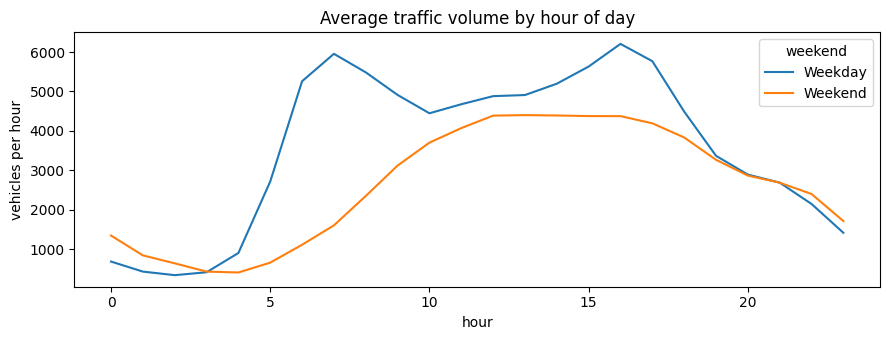

In [4]:
tmp = full.copy()
tmp["hour"] = tmp.index.hour
tmp["weekend"] = np.where(tmp.index.dayofweek >= 5, "Weekend", "Weekday")
hourly = tmp.groupby(["hour", "weekend"])["traffic_volume"].mean().unstack()
hourly.plot(figsize=(9, 3.5), title="Average traffic volume by hour of day")
plt.ylabel("vehicles per hour"); plt.tight_layout()
plt.savefig("eda_hourly.png", dpi=150); plt.show()

## 4. Features and congestion levels

In [5]:
d = full.copy()
d["hour"] = d.index.hour
d["dayofweek"] = d.index.dayofweek
d["month"] = d.index.month
d["is_weekend"] = (d["dayofweek"] >= 5).astype(int)
for lag in [1, 2, 3, 24, 168]:                       # traffic 1h, 2h, 3h, 1 day, 1 week earlier
    d[f"lag_{lag}"] = d["traffic_volume"].shift(lag, freq="h").reindex(d.index)
d["roll_3h"] = (d["lag_1"] + d["lag_2"] + d["lag_3"]) / 3
d = d.dropna()

FEATURES = ["hour", "dayofweek", "month", "is_weekend", "is_holiday",
            "temp_c", "rain_1h", "snow_1h", "clouds_all",
            "lag_1", "lag_2", "lag_3", "lag_24", "lag_168", "roll_3h"]

split_idx = int(len(d) * 0.8)
train, test = d.iloc[:split_idx], d.iloc[split_idx:]

# congestion thresholds come from the TRAINING period only (no information from the test period)
q1, q2 = train["traffic_volume"].quantile([0.33, 0.66])
print(f"Low <= {q1:.0f} vehicles/hour < Medium <= {q2:.0f} < High")

def to_level(v):
    return np.where(v <= q1, 0, np.where(v <= q2, 1, 2))

y_train, y_test = to_level(train["traffic_volume"]), to_level(test["traffic_volume"])
X_train, X_test = train[FEATURES], test[FEATURES]
print("train:", X_train.shape, " test:", X_test.shape)
print("test class balance:", dict(zip(LABELS, np.bincount(y_test) / len(y_test))))

Low <= 2239 vehicles/hour < Medium <= 4562 < High
train: (34063, 15)  test: (8516, 15)
test class balance: {'Low': np.float64(0.32538750587130105), 'Medium': np.float64(0.32374354156881163), 'High': np.float64(0.35086895255988726)}


## 5. Models

In [6]:
preds = {}
preds["Persistence baseline (same level as previous hour)"] = to_level(test["lag_1"])

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}
fitted = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    fitted[name] = m
    preds[name] = m.predict(X_test)

## 6. Evaluation

In [7]:
rows = []
for name, p in preds.items():
    rows.append({"Model": name,
                 "Accuracy (%)": round(accuracy_score(y_test, p) * 100, 1),
                 "Macro F1": round(f1_score(y_test, p, average="macro"), 3)})
results = pd.DataFrame(rows).set_index("Model")
results.to_csv("results.csv")
results

,Accuracy (%),Macro F1
Model,,
Persistence baseline (same level as previous hour),80.4,0.802
Logistic Regression,90.0,0.900
Random Forest,94.5,0.945
Gradient Boosting,94.7,0.946


Best model: Gradient Boosting


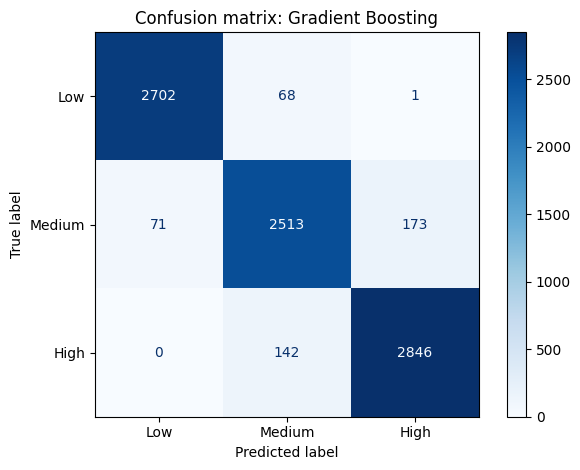

In [8]:
best = results.drop(index=results.index[0])["Accuracy (%)"].idxmax()   # best real model (not the baseline)
print("Best model:", best)
ConfusionMatrixDisplay.from_predictions(y_test, preds[best], display_labels=LABELS, cmap="Blues")
plt.title(f"Confusion matrix: {best}"); plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150); plt.show()

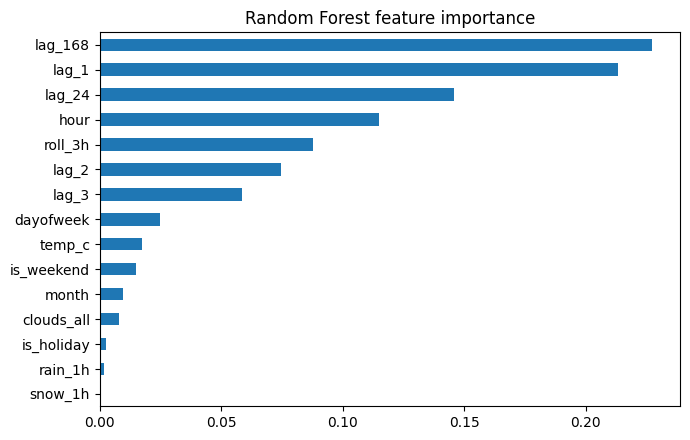

In [9]:
rf = fitted["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(7, 4.5), title="Random Forest feature importance")
plt.tight_layout(); plt.savefig("feature_importance.png", dpi=150); plt.show()

## 7. Findings

Gradient Boosting performed best (accuracy 94.7%, macro F1 0.946), closely followed by Random Forest (94.5%, macro F1 0.945). Both clearly beat the persistence baseline (80.4% accuracy, about 14 points lower) and Logistic Regression (90.0%). The 0.2-point gap between Gradient Boosting and Random Forest is too small to call one better. According to the feature importance chart, the most important features were lag_168 (traffic at the same hour one week earlier), lag_1 (traffic one hour earlier) and lag_24 (traffic at the same hour the previous day), followed by the hour of day. Weather features such as rain, snow and temperature contributed very little. This analysis used one highway, one city and data from 2012 to 2018, and congestion levels are defined relative to this dataset, so the results may not apply to other roads.
